# Pattern-Matching NILM

## Imports

In [89]:
import os
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

from fastdtw import fastdtw

## Directories

In [63]:
base_dir = os.getcwd()
processed_data_dir = os.path.join(base_dir, 'processed_data')

results_dir = os.path.join(base_dir, 'results')
os.makedirs(results_dir, exist_ok=True)

## Load Data

In [64]:
processed_data_filepath = os.path.join(processed_data_dir, 'ampds_dataset.npz')
data = np.load(processed_data_filepath)

# Check Data
print(data.files)

# check shape of x_norm and y_norm
print("x_norm shape:", data["x_norm"].shape)
print("y_norm shape:", data["y_norm"].shape)

# Check the index shapes
# Create a table of input/output index shapes for each dataset split
dataset_names = sorted({
    key.rsplit('_', 1)[0]
    for key in data.files
    if key.endswith(('_inp', '_out'))})

index_shapes = pd.DataFrame([
    {
        'Dataset': name,
        'Input index shape': data[f'{name}_inp'].shape if f'{name}_inp' in data.files else None,
        'Output index shape': data[f'{name}_out'].shape if f'{name}_out' in data.files else None}
    for name in dataset_names])

display(index_shapes)

['appliance_names', 'x_norm', 'y_norm', 'x_min', 'x_max', 'y_min', 'y_max', 'train_inp', 'train_out', 'val_inp', 'val_out', 'test_inp', 'test_out', 'T_limit', 'train_val_test_split', 'window_length', 'stride']
x_norm shape: (1000, 6)
y_norm shape: (1000, 22, 4)


,Dataset,Input index shape,Output index shape
0,test,"(83,)","(83,)"
1,train,"(492,)","(492,)"
2,val,"(164,)","(164,)"


## Create Template Database

Pattern-matching algorithms work by comparing new inputs with examples stored from the training data. Here, the normalizes data and training input/output indices already define those examples, so there's no need to build a separate template database.

## Time-series data frame comparison

### Feature distance

One way to compare time-series frames is to summarize each with a feature vector, then measure the difference between those vectors. Possible features include the mean, minimum, maximum, standard deviation, root-mean-square (RMS), and energy.

In [65]:
def compute_feature_vector(x_win, feature_selection='all'):

    funcs = {
        'mean': lambda x: np.mean(x),
        'min': lambda x: np.min(x),
        'max': lambda x: np.max(x),
        'std': lambda x: np.std(x),
        'rms': lambda x: np.mean(x**2),
        'energy': lambda x: np.sum(x**2)}

    if feature_selection == 'all': feature_selection = list(funcs.keys())
    out = np.column_stack([funcs[name](x_win) for name in feature_selection])
    return out

In [21]:
def feature_distance(vector1, vector2): return np.linalg.norm(vector1 - vector2)

Recomputing template features for every test-frame comparison would be inefficient. Instead, we compute and store each template's feature vector once, then use a lookup keyed by the template's input index to retrieve it.

In [22]:
feature_lookup = {
    int(i): compute_feature_vector(data['x_norm'][i : i + data['window_length'].item()])
    for i in data['train_inp']}

In [23]:
print("Feature lookup dictionary length:", len(feature_lookup))

columns = ["Mean", "Min", "Max", "Std", "RMS", "Energy"]
df = pd.DataFrame([v.ravel() for v in list(feature_lookup.values())[:5]],
                  index=list(feature_lookup)[:5], columns=columns)
df.index.name = "Template Start Index"
display(df.reset_index().style.hide(axis="index"))

Feature lookup dictionary length: 492


Template Start Index,Mean,Min,Max,Std,RMS,Energy
291,0.064807,0.000000,0.320320,0.108713,0.016018,2.883313
256,0.227654,0.000000,0.394043,0.122000,0.066710,12.007883
855,0.222738,0.000000,0.884885,0.302812,0.141307,25.435296
228,0.075722,0.000000,0.390059,0.102117,0.016162,2.909131
53,0.109409,0.000000,1.000000,0.160628,0.037772,6.798902


### Correlation

Correlation provides another way to comprare two time-series frames. This function calculates their Pearson Correlation. Pearson correlation measures how strongly two variables move together in a linear way. The function flattens each frame into a one-dimensional array, computes their correlation matrix, and selects the value comparing the two frames. The result ranges from -1 (opposing patterns) to +1 (strongly similar patterns). A value near 0 indicates little linear relationship.

In [24]:
def compute_correlation(frame1, frame2): return np.corrcoef(frame1.flatten(), frame2.flatten())[0, 1]

### Dynamic Time Warping

Dynamic time warping (DTW) compares two time-series segments by aligning their points flexibly, allowing similar patterns to occur at different speeds or be shifted in time. It finds the lowest-cost alignment between the sequences. The `distance` is the accumulates cost of the best alisngment. A smaller DTW distance means they are more similar. The `path` is the alignment as pairs of indices. Each pair indicates which point in the first sequence corresponds to a point in the second. A point may appear in multiple pairs to account for timing differences.

In [25]:
def compute_dtw(frame1, frame2):
    
    distance, path = fastdtw(frame1.flatten(), frame2.flatten())
    return distance, path

## Pattern Matching

### Compute Template Distances

In [68]:
def pattern_matching(data, methods='all', feature_selection='all', feature_lookup=None):
    
    columns = [
        'test frame start index',
        'template start index',
        'feature distance',
        'pearson correlation',
        'dtw distance']

    if methods == 'all': methods = ['feature_distance', 'pearson_correlation', 'dtw_distance']

    window_length = int(data['window_length'].item())
    train_indices = data['train_inp']
    rows = []

    for test_index in tqdm(data['test_inp'], desc='Predicting'):
        test_index = int(test_index)
        test_frame = data['x_norm'][test_index:test_index + window_length]
        test_features = (
            compute_feature_vector(test_frame, feature_selection)
            if 'feature_distance' in methods else None)

        for template_index in train_indices:

            template_index = int(template_index)
            row = {
                'test frame start index': test_index,
                'template start index': template_index,
                'feature distance': np.nan,
                'pearson correlation': np.nan,
                'dtw distance': np.nan}

            if 'feature_distance' in methods: 
                template_features = feature_lookup[template_index]
                row['feature distance'] = feature_distance(test_features, template_features)

            if 'pearson_correlation' in methods:
                template_frame = data['x_norm'][template_index:template_index + window_length]
                row['pearson correlation'] = compute_correlation(test_frame, template_frame)

            if 'dtw_distance' in methods:
                template_frame = data['x_norm'][template_index:template_index + window_length]
                row['dtw distance'] = compute_dtw(test_frame, template_frame)[0]

            rows.append(row)

    return pd.DataFrame(rows, columns=columns)


In [69]:
frame_distances_df = pattern_matching(data, methods=['feature_distance', 'pearson_correlation', 'dtw_distance'], feature_selection='all', feature_lookup=feature_lookup)
display(frame_distances_df.head(10).style.hide(axis="index"))

Predicting:   0%|          | 0/83 [00:00<?, ?it/s]

test frame start index,template start index,feature distance,pearson correlation,dtw distance
935,291,27.424110,0.975194,31.500680
935,256,18.300391,0.363419,36.626726
935,855,4.863509,0.967745,15.058787
935,228,27.396730,0.740312,35.926808
935,53,23.500427,-0.071206,37.593782
935,373,21.739752,0.694112,39.408443
935,832,0.903420,0.899476,39.749846
935,288,27.482072,0.976428,31.766761
935,701,14.437018,0.980194,21.594109
935,722,0.174199,0.715638,45.824042


In [56]:
frame_distances_df_save_filepath = os.path.join(results_dir, 'pattern_matching_results.csv')
frame_distances_df.to_csv(frame_distances_df_save_filepath, index=False)

### Predict Appliance Profiles

In [58]:
def compute_mae(frame1, frame2): return np.mean(np.abs(frame1 - frame2))

In [59]:
def compute_rmse(frame1, frame2): return np.sqrt(np.mean((frame1 - frame2) ** 2))

In [60]:
def compute_sae(frame1, frame2): return np.sum(np.abs(frame1 - frame2))

In [110]:
def predict(test_frame_start_idx, frame_distances_df):
    
    candidates = frame_distances_df.loc[frame_distances_df['test frame start index'] == test_frame_start_idx]
    # match = candidates.loc[candidates['feature distance'].idxmin()]
    # match = candidates.loc[candidates['pearson correlation'].idxmax()]
    match = candidates.loc[candidates['dtw distance'].idxmin()]
    template_index = int(match['template start index'])

    feature_distance = float(match['feature distance'])
    pearson_correlation = float(match['pearson correlation'])
    dtw_distance = float(match['dtw distance'])
    
    return template_index, feature_distance, pearson_correlation, dtw_distance

In [111]:
def compute_error_metrics(test_frame_start_idx, template_start_idx, window_length, y_norm):

    actual = y_norm[test_frame_start_idx : test_frame_start_idx  + window_length]
    predicted = y_norm[template_start_idx : template_start_idx + window_length]

    return {
        'mae': compute_mae(actual, predicted),
        'rmse': compute_rmse(actual, predicted),
        'sae': compute_sae(actual, predicted)}

In [112]:
prediction_results = {}

for appliance_idx, appliance in enumerate(data['appliance_names']):

    rows = []
    appliance_data = data['y_norm'][:, appliance_idx]

    for test_frame_start_idx in data['test_inp']:

        template_start_idx, feature_distance, pearson_correlation, dtw_distance = predict(test_frame_start_idx, frame_distances_df)
        error_metrics = compute_error_metrics(test_frame_start_idx, template_start_idx, data['window_length'].item(), appliance_data)

        rows.append({
            'test frame start idx': test_frame_start_idx,
            'template start idx': template_start_idx,
            'feature distance': feature_distance,
            'pearson correlation': pearson_correlation,
            'dtw_distance': dtw_distance,
            'mae': error_metrics['mae'],
            'rmse': error_metrics['rmse'],
            'sae': error_metrics['sae']
        })

    prediction_results[appliance] = (
        pd.DataFrame(rows)
        .sort_index())

In [113]:
for appliance in data['appliance_names']:
    display(prediction_results[appliance].head(5).style.set_caption(f'{appliance} Prediction'))

,test frame start idx,template start idx,feature distance,pearson correlation,dtw_distance,mae,rmse,sae
0,935,850,3.755429,0.979950,9.096367,0.085085,0.085085,10.210210
1,948,858,4.996188,0.988166,7.773026,0.090090,0.090090,10.810811
2,944,858,4.686003,0.989834,7.306602,0.086086,0.086086,10.330330
3,888,858,3.842722,0.973909,10.796388,0.030030,0.030030,3.603604
4,953,858,5.452163,0.986739,9.844083,0.095095,0.095095,11.411411


,test frame start idx,template start idx,feature distance,pearson correlation,dtw_distance,mae,rmse,sae
0,935,850,3.755429,0.979950,9.096367,0.000000,0.000000,0.000000
1,948,858,4.996188,0.988166,7.773026,0.000000,0.000000,0.000000
2,944,858,4.686003,0.989834,7.306602,0.000000,0.000000,0.000000
3,888,858,3.842722,0.973909,10.796388,0.000000,0.000000,0.000000
4,953,858,5.452163,0.986739,9.844083,0.000000,0.000000,0.000000


,test frame start idx,template start idx,feature distance,pearson correlation,dtw_distance,mae,rmse,sae
0,935,850,3.755429,0.979950,9.096367,0.052899,0.060057,6.347879
1,948,858,4.996188,0.988166,7.773026,0.057738,0.064133,6.928597
2,944,858,4.686003,0.989834,7.306602,0.057271,0.063381,6.872470
3,888,858,3.842722,0.973909,10.796388,0.055880,0.067118,6.705646
4,953,858,5.452163,0.986739,9.844083,0.046330,0.052554,5.559603


,test frame start idx,template start idx,feature distance,pearson correlation,dtw_distance,mae,rmse,sae
0,935,850,3.755429,0.979950,9.096367,0.157870,0.289787,18.944444
1,948,858,4.996188,0.988166,7.773026,0.186111,0.317445,22.333333
2,944,858,4.686003,0.989834,7.306602,0.184259,0.309902,22.111111
3,888,858,3.842722,0.973909,10.796388,0.200926,0.326866,24.111111
4,953,858,5.452163,0.986739,9.844083,0.171296,0.307067,20.555556


,test frame start idx,template start idx,feature distance,pearson correlation,dtw_distance,mae,rmse,sae
0,935,850,3.755429,0.979950,9.096367,0.000000,0.000000,0.000000
1,948,858,4.996188,0.988166,7.773026,0.000000,0.000000,0.000000
2,944,858,4.686003,0.989834,7.306602,0.000000,0.000000,0.000000
3,888,858,3.842722,0.973909,10.796388,0.000000,0.000000,0.000000
4,953,858,5.452163,0.986739,9.844083,0.000000,0.000000,0.000000


,test frame start idx,template start idx,feature distance,pearson correlation,dtw_distance,mae,rmse,sae
0,935,850,3.755429,0.979950,9.096367,0.341941,0.474789,41.032875
1,948,858,4.996188,0.988166,7.773026,0.158687,0.261106,19.042410
2,944,858,4.686003,0.989834,7.306602,0.159427,0.246324,19.131292
3,888,858,3.842722,0.973909,10.796388,0.202433,0.330888,24.291997
4,953,858,5.452163,0.986739,9.844083,0.149516,0.300728,17.941908


... (10 outputs left out)

,test frame start idx,template start idx,feature distance,pearson correlation,dtw_distance,mae,rmse,sae
0,935,850,3.755429,0.979950,9.096367,0.000000,0.000000,0.000000
1,948,858,4.996188,0.988166,7.773026,0.000000,0.000000,0.000000
2,944,858,4.686003,0.989834,7.306602,0.000000,0.000000,0.000000
3,888,858,3.842722,0.973909,10.796388,0.000000,0.000000,0.000000
4,953,858,5.452163,0.986739,9.844083,0.000000,0.000000,0.000000


,test frame start idx,template start idx,feature distance,pearson correlation,dtw_distance,mae,rmse,sae
0,935,850,3.755429,0.979950,9.096367,0.000000,0.000000,0.000000
1,948,858,4.996188,0.988166,7.773026,0.000000,0.000000,0.000000
2,944,858,4.686003,0.989834,7.306602,0.000000,0.000000,0.000000
3,888,858,3.842722,0.973909,10.796388,0.000000,0.000000,0.000000
4,953,858,5.452163,0.986739,9.844083,0.000000,0.000000,0.000000


,test frame start idx,template start idx,feature distance,pearson correlation,dtw_distance,mae,rmse,sae
0,935,850,3.755429,0.979950,9.096367,0.138048,0.330210,16.565715
1,948,858,4.996188,0.988166,7.773026,0.295523,0.482230,35.462702
2,944,858,4.686003,0.989834,7.306602,0.295523,0.482230,35.462702
3,888,858,3.842722,0.973909,10.796388,0.203088,0.394974,24.370561
4,953,858,5.452163,0.986739,9.844083,0.296661,0.481976,35.599353


,test frame start idx,template start idx,feature distance,pearson correlation,dtw_distance,mae,rmse,sae
0,935,850,3.755429,0.979950,9.096367,0.142353,0.235651,17.082353
1,948,858,4.996188,0.988166,7.773026,0.117717,0.216001,14.126059
2,944,858,4.686003,0.989834,7.306602,0.130132,0.227392,15.615782
3,888,858,3.842722,0.973909,10.796388,0.112510,0.197200,13.501208
4,953,858,5.452163,0.986739,9.844083,0.117390,0.217290,14.086843


### Determine Best Distance Metric

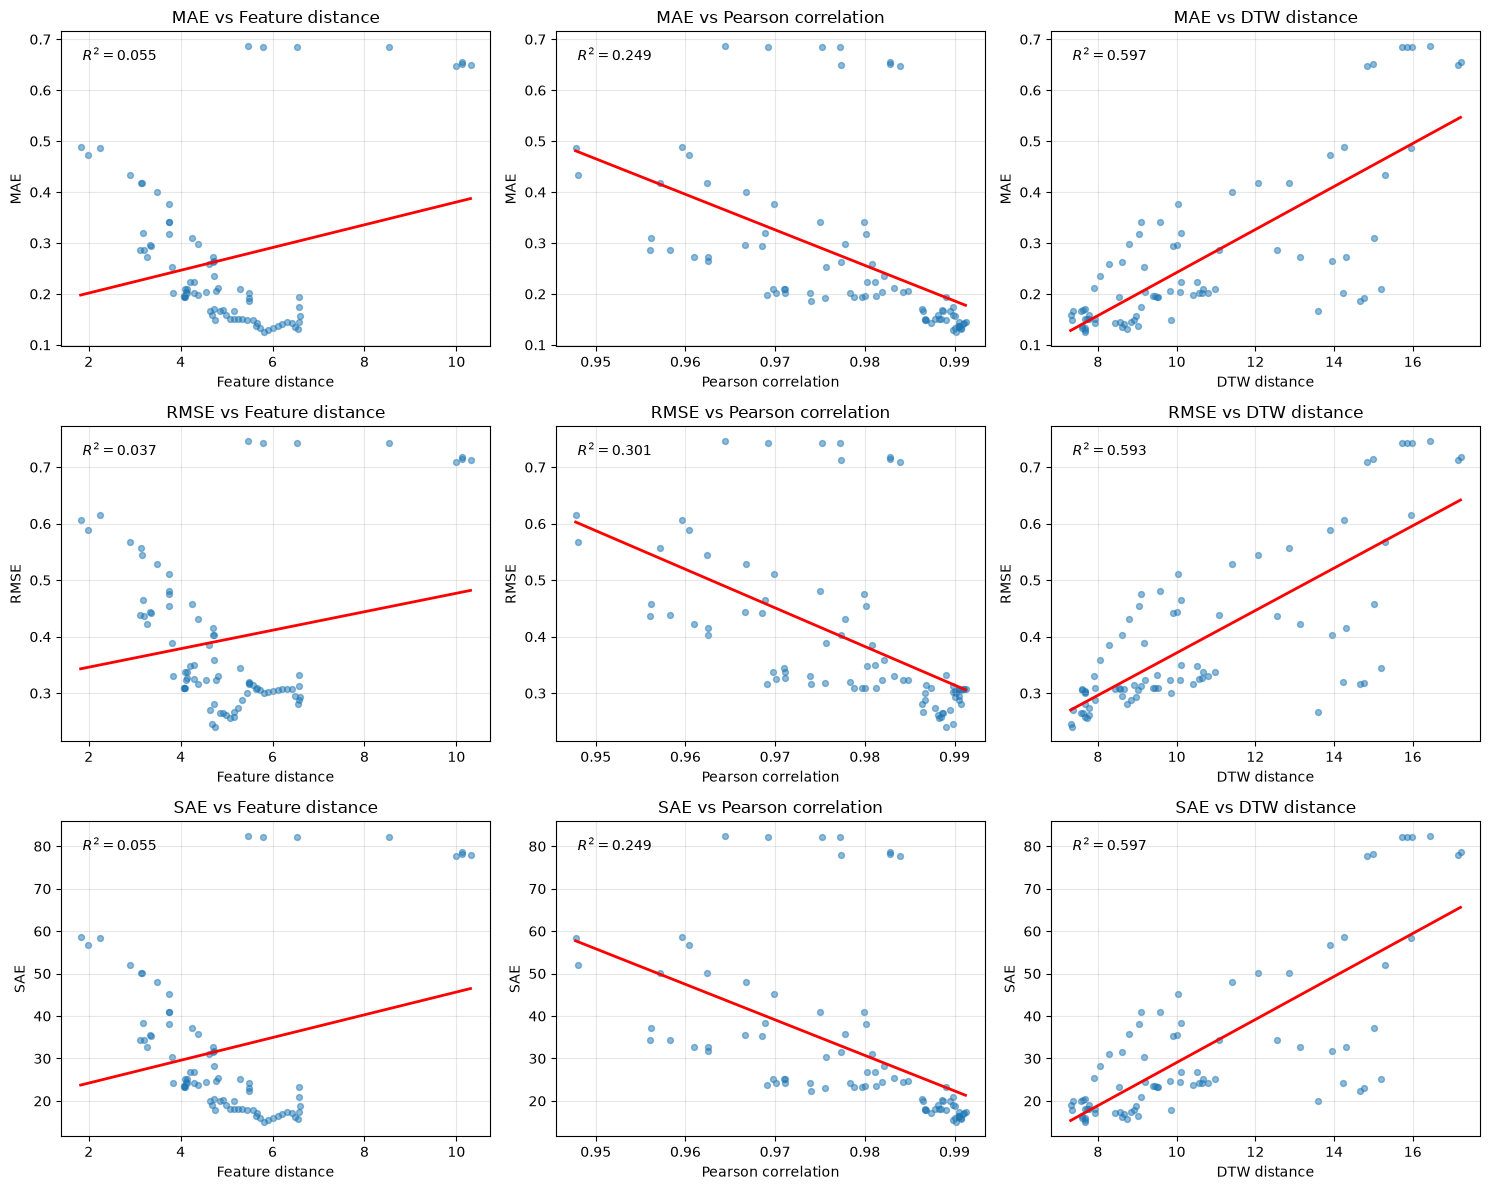

In [114]:
# Combine per-appliance predictions and errors into one dataframe
plot_df = prediction_results['DWE']

x_metrics = [
    ('feature distance', 'Feature distance'),
    ('pearson correlation', 'Pearson correlation'),
    ('dtw_distance', 'DTW distance')
]
y_metrics = ['mae', 'rmse', 'sae']

fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for row, error_metric in enumerate(y_metrics):
    for col, (distance_col, distance_label) in enumerate(x_metrics):
        ax = axes[row, col]

        points = plot_df[[distance_col, error_metric]].dropna()
        x = points[distance_col].to_numpy(dtype=float)
        y = points[error_metric].to_numpy(dtype=float)

        ax.scatter(x, y, alpha=0.5, s=18)

        if len(x) >= 2 and np.unique(x).size >= 2:
            slope, intercept = np.polyfit(x, y, 1)
            x_line = np.linspace(x.min(), x.max(), 100)
            y_line = slope * x_line + intercept
            ax.plot(x_line, y_line, color='red', linewidth=2)

            y_pred = slope * x + intercept
            ss_res = np.sum((y - y_pred) ** 2)
            ss_tot = np.sum((y - y.mean()) ** 2)
            r2 = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan
            ax.text(
                0.05, 0.95, f'$R^2 = {r2:.3f}$',
                transform=ax.transAxes, va='top'
            )

        ax.set_title(f'{error_metric.upper()} vs {distance_label}')
        ax.set_xlabel(distance_label)
        ax.set_ylabel(error_metric.upper())
        ax.grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

Pearson correlation performs the best.

## Final Evaluation

In [115]:
target_appliance = 'DWE'
appliance_idx = list(data['appliance_names']).index(target_appliance)
appliance_results = prediction_results[target_appliance]

window_length = int(data['window_length'].item())

y_true = np.asarray(data['y_norm'])[:, appliance_idx]
y_pred = np.full_like(y_true, np.nan, dtype=float)

for _, row in appliance_results.iterrows():
    test_start = int(row['test frame start idx'])
    template_start = int(row['template start idx'])

    predicted_frame = y_true[template_start:template_start + window_length]
    end = min(test_start + len(predicted_frame), len(y_true))

    y_pred[test_start:end] = predicted_frame[:end - test_start]

valid = ~np.isnan(y_pred)
y_true = y_true[valid]
y_pred = y_pred[valid]

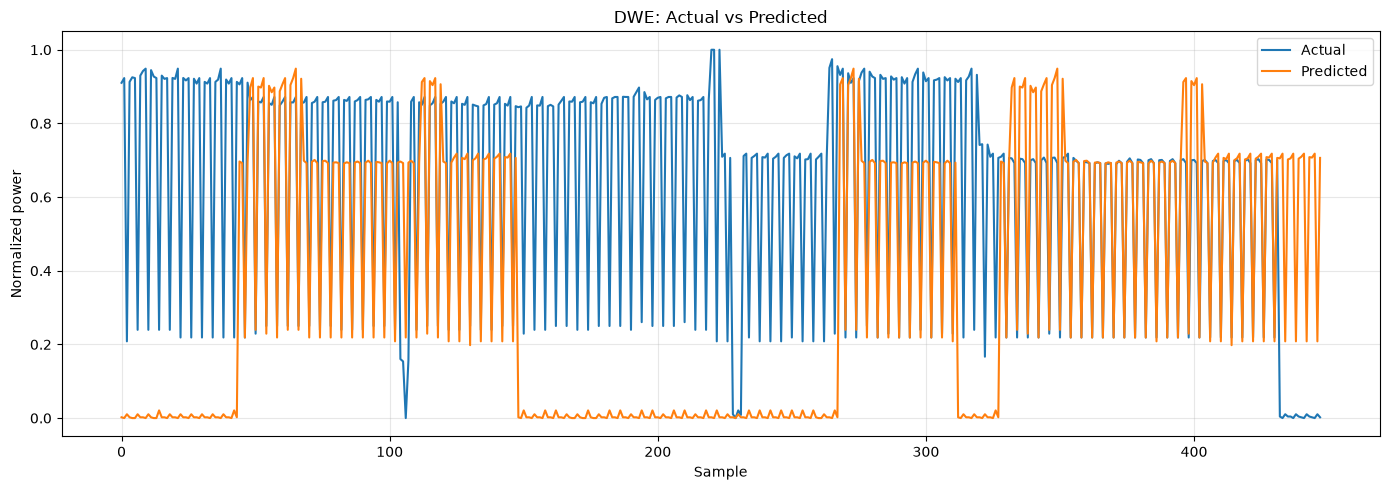

In [116]:
plt.figure(figsize=(14, 5))
plt.plot(np.arange(len(y_true)), y_true, label='Actual', linewidth=1.5)
plt.plot(np.arange(len(y_pred)), y_pred, label='Predicted', linewidth=1.5)
plt.xlabel('Sample')
plt.ylabel('Normalized power')
plt.title(f'{target_appliance}: Actual vs Predicted')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()